In [3]:
# Find the repo root (the folder containing src/paths.py), put src/ on the import
# path, and run from the repo root so relative data/ and calibration/ paths resolve.
import os, sys
_root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_root, "src", "paths.py")):
    _parent = os.path.dirname(_root)
    if _parent == _root:
        raise RuntimeError("Could not find src/paths.py above the working directory")
    _root = _parent
if os.path.join(_root, "src") not in sys.path:
    sys.path.insert(0, os.path.join(_root, "src"))
os.chdir(_root)

In [4]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import random
import math
import matplotlib.pyplot as plt
from pyomo.environ import *
from optimization_utils import *
from param_loader import METANET_Params
from simulation_utils import *
from mpc_utils import *
from eval_metrics import *
import os
import time

In [5]:
# print ipopt version
!ipopt --version

Ipopt 3.14.16 (Darwin x86_64), ASL(20160307)


In [6]:
import numpy as np

# Same day as cell 4, which reloads this data afterwards
root_path = "data/i24/i24_11_29"
calib_path = "calibration/i24/i24_11_29"

# ---- load data ----
q_hat   = np.load(f"{root_path}/q_hat.npy")
rho_hat = np.load(f"{root_path}/rho_hat.npy")
lane_map = np.load(f"{root_path}/lane_mapping.npy")[1:-1]
lane_mapping = {i: float(lane_map[i]) for i in range(len(lane_map))}
ramp_mapping = {
    "on_ramps":  np.load(f"{root_path}/on_ramp_mapping.npy")[1:-1],
    "off_ramps": np.load(f"{root_path}/off_ramp_mapping.npy")[1:-1],
}

rho_hat = np.where(rho_hat == 0.0, 1e-3, rho_hat)
q_hat = np.where(q_hat == 0.0, 1e-3, q_hat)
v_hat = q_hat / rho_hat
scaled_rho_hat = rho_hat[:, 1:-1] / lane_map

downstream_density = smooth_inflow(rho_hat[:, -1])
data_inflow = smooth_inflow(q_hat[:, 0])
init_traffic_state = (rho_hat[0, 1:-1]/lane_map, v_hat[0, 1:-1], data_inflow[0], 0)

# ---- derived v_hat (this is what the calibration actually fits) ----
v_hat     = q_hat / rho_hat

In [7]:
print(rho_hat.shape)
print(q_hat.shape)

(360, 16)
(360, 16)


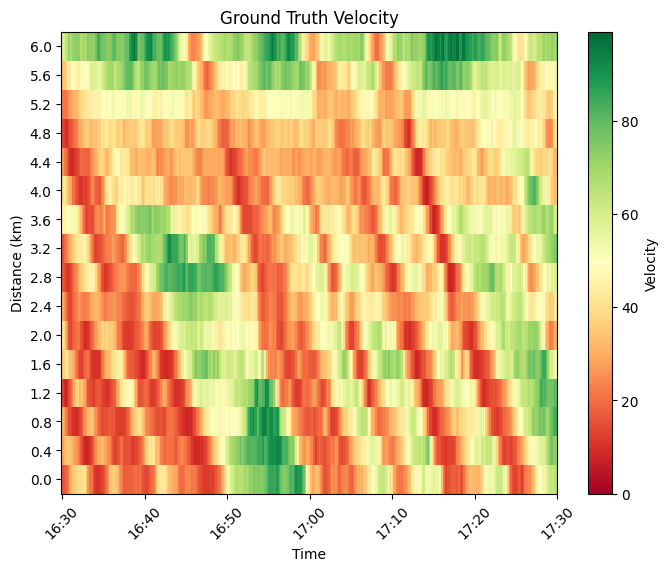

In [8]:
def to_wallclock(tick_minutes, start_hour):
    labels = []
    for m in tick_minutes:
        total_minutes = start_hour * 60 + m
        h = int(total_minutes // 60) % 24
        mn = int(total_minutes % 60)
        labels.append(f"{h:02d}:{mn:02d}")
    return labels

start_wallclock_time = 16.5
plt.figure(figsize=(8, 6))
plt.imshow(v_hat.T, aspect="auto", origin="lower", cmap="RdYlGn", interpolation="none", vmin=0)
plt.colorbar(label="Velocity")

# Convert time steps to wall clock time
time_steps = v_hat.shape[0]+1
time_ticks = list(range(0, time_steps, int(time_steps / 6)))
# Correct - each step is 10 seconds = 10/60 minutes
tick_minutes = [i * 10 / 60 for i in time_ticks]
time_labels = to_wallclock(tick_minutes, start_wallclock_time)

# Convert space steps to km
space_steps = v_hat.shape[1]
space_labels = [f"{(i * 400) / 1000:.1f}" for i in range(0, space_steps, int(space_steps / 10))]
space_ticks = list(range(0, space_steps, int(space_steps / 10)))

plt.xticks(time_ticks, time_labels, rotation=45)
plt.yticks(space_ticks, space_labels)

plt.title("Ground Truth Velocity")
plt.xlabel("Time")
plt.ylabel("Distance (km)")
plt.show()

In [9]:
random.seed(1)
np.random.seed(1)

np.set_printoptions(suppress=True)

T = 10 / 3600
l = 0.4
num_calibrated_segments = rho_hat.shape[1]-2
include_ramping = True
varylanes = False

In [10]:
import logging

logging.getLogger('pyomo.core').setLevel(logging.ERROR)

In [ ]:
start = time.time()
calibrate_params_mpc(
    rho_hat,
    q_hat,
    T,
    l,
    90,
    pred_h = 120,
    num_calibrated_segments=num_calibrated_segments,
    include_ramping=include_ramping,
    ramp_mapping=None if not include_ramping else ramp_mapping,
    lane_mapping=lane_mapping,
    varylanes=varylanes,
    smoothing=False,
    constraint_tol=1e-9,
    verbose=True,
    results_root_dir=f"{calib_path}/calibration_dynamic_smooth", # Change accordingly
    robust_opt=None, #robust_opt_params, 
    warmstart=None,
    stable_params=False,
    separate_boundary_conditions={"downstream_density": downstream_density, "initial_flow": data_inflow},
    use_A_regularizer=False,
)

print("Calibration took", time.time() - start, "seconds")

In [ ]:
# Run dymamic calibration for different control horizons
for (control_h, pred_hor) in [(6, 18), (12, 36), (30, 60), (60, 90), (90, 120), (120, 150), (180, 240), (360, 360)]:
    calibrate_params_mpc(
        rho_hat[:, 1:-1],
        q_hat[:, 1:-1],
        T,
        l,
        control_h,
        pred_h = pred_hor,
        num_calibrated_segments=num_calibrated_segments,
        include_ramping=include_ramping,
        ramp_mapping=None if not include_ramping else ramp_mapping,
        lane_mapping=lane_mapping,
        varylanes=varylanes,
        smoothing=False,
        constraint_tol=1e-12,
        verbose=True,
        results_root_dir=f"{calib_path}/calibration_dynamic_smooth", #synthetic_calibration_results",
        robust_opt=None, #robust_opt_params, 
        warmstart=None,
        stable_params=True,
        separate_boundary_conditions={"downstream_density": downstream_density, "initial_flow": data_inflow},
        use_A_regularizer=False,
        tee=True,
        min_oscillations=False
    )

In [ ]:
# Run Static calibration if path doesn't already exist
RESULTS_DIR = f"{calib_path}/calibration_static/fixed_ramping"

if not os.path.exists(RESULTS_DIR):
    os.makedirs(RESULTS_DIR)

    results = run_calibration(
        rho_hat[:, 1:-1],
        q_hat[:, 1:-1],
        T,
        l,
        num_calibrated_segments=num_calibrated_segments,
        varylanes=varylanes,
        sep_boundary_conditions={"downstream_density": downstream_density, "initial_flow": data_inflow},
        #lane_mapping={0:4, 1:4, 24, 3:4.5, 4:5, 5:5, 6:5, 7:5, 8:5, 9:4, 10:4, 11:4, 12:4.5, 13:4},
        include_ramping=include_ramping,
        lane_mapping=lane_mapping,
        ramp_mapping=ramp_mapping,
        smoothing=False,
        constraint_tol=1e-12,
        warmstart= None, #"calibration_results/robust_S10_0001",
        robust_opt=None,
        time_varying_ramps=False,
        fixed_inflows=None,
        use_options_file=True
    )

    np.save(f"{RESULTS_DIR}/tau.npy", results["tau"])
    np.save(f"{RESULTS_DIR}/K.npy", results["K"])
    np.save(f"{RESULTS_DIR}/eta_high.npy", results["eta_high"])
    np.save(f"{RESULTS_DIR}/rho_crit.npy", results["rho_crit"])
    np.save(f"{RESULTS_DIR}/v_free.npy", results["v_free"])
    np.save(f"{RESULTS_DIR}/a.npy", results["a"])
    np.save(f"{RESULTS_DIR}/num_lanes.npy", results["num_lanes"])
    np.save(f"{RESULTS_DIR}/q_pred.npy", results["q_pred"])
    np.save(f"{RESULTS_DIR}/v_pred.npy", results["v_pred"])
    np.save(f"{RESULTS_DIR}/rho_pred.npy", results["rho_pred"])
    # np.save("r_array.npy", r_array)
    # if include_ramping:
        # np.save("gamma_array.npy", gamma_array)
    np.save(f"{RESULTS_DIR}/beta_array.npy", results["beta"])
    np.save(f"{RESULTS_DIR}/r_inflow_array.npy", results["r_inflow"])

In [21]:
print("Simulating with dynamic calibrated parameters...")
# stop printing in scientific notation
np.set_printoptions(suppress=True)
DYN_RESULTS_DIR = f"{calib_path}/calibration_dynamic_smooth"

dyn_params = METANET_Params(path=DYN_RESULTS_DIR, num_segments=num_calibrated_segments, num_timesteps=360, control_h=60).get_params()
#mpc_params = METANET_Params(path="itsc_final/mpc_calibration_results", control_h=1, num_timesteps=360).get_params()

rho_sim, v_sim, _, tts_sim = run_metanet_sim(
    T, 
    l, 
    init_traffic_state,
    data_inflow,
    downstream_density/lane_map[-1],
    dyn_params,
    vsl_speeds=None,
    lanes=lane_mapping, #{i: num_lanes_array[i] for i in range(num_calibrated_segments)},
    plotting=True,
    real_data=True
)
# run_metanet_sim also returns the initial state; drop the extra last step to match v_hat (360 steps)
dyn_rho_sim, dyn_v_sim = rho_sim[0:-1, :], v_sim[0:-1, :]
print(dyn_rho_sim.shape, dyn_v_sim.shape)


Simulating with dynamic calibrated parameters...
(360, 14) (360, 14)


In [22]:
print("Simulating with static calibrated parameters...")
# stop printing in scientific notation
np.set_printoptions(suppress=True)
STAT_RESULTS_DIR = f"{calib_path}/calibration_static/fixed_ramping"

params = METANET_Params(path=STAT_RESULTS_DIR, num_segments=num_calibrated_segments, num_timesteps=360, control_h=None).get_params()
#mpc_params = METANET_Params(path="itsc_final/mpc_calibration_results", control_h=1, num_timesteps=360).get_params()

rho_sim, v_sim, _, _ = run_metanet_sim(
    T, 
    l, 
    init_traffic_state,
    data_inflow,
    downstream_density/lane_map[-1],
    params,
    vsl_speeds=None,
    lanes=lane_mapping, #{i: num_lanes_array[i] for i in range(num_calibrated_segments)},
    plotting=True,
    real_data=True
)
static_v_sim = v_sim[0:-1, :]
static_rho_sim = rho_sim[0:-1, :]

Simulating with static calibrated parameters...


True shape: (360, 14)
Max true density: 96.07781298749916


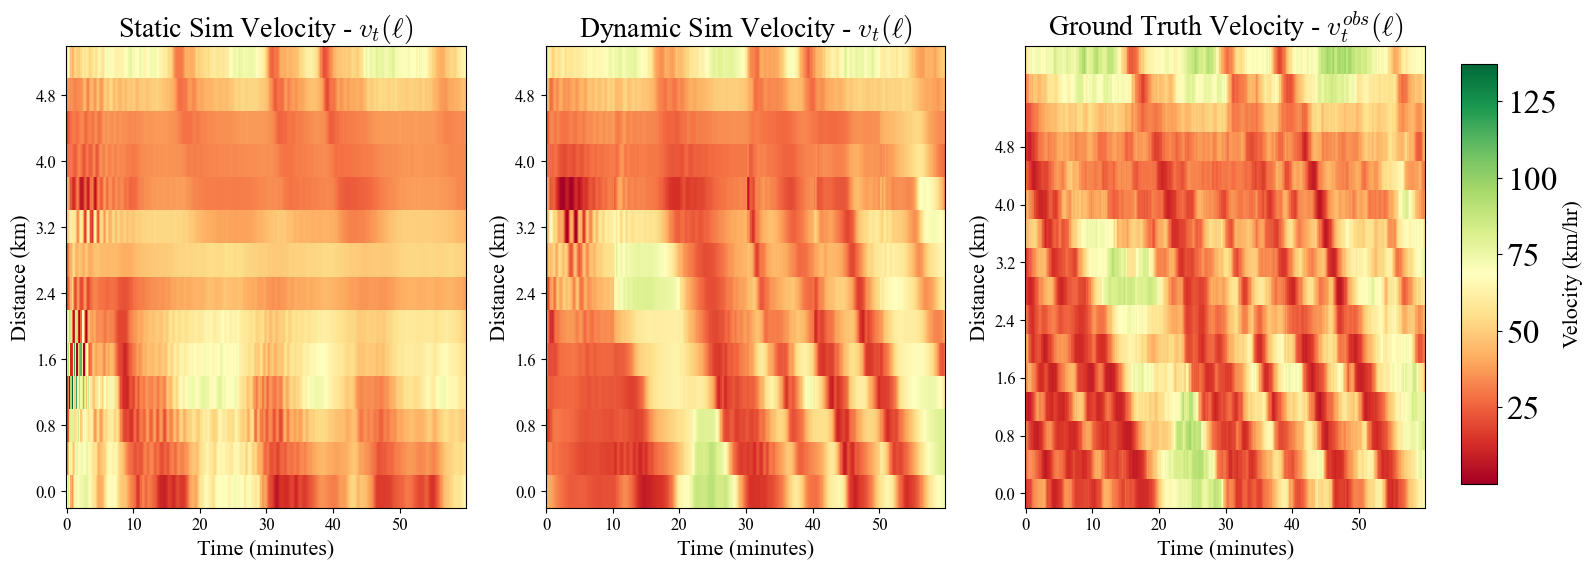

In [23]:
v_plot_true = v_hat[:, 1:-1]
# v_pred = np.load(STAT_RESULTS_DIR + "/v_pred.npy")
print("True shape:", v_plot_true.shape)
print("Max true density:", np.max(v_plot_true))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# --- Compute common color scale ---
vmin = min(
    np.min(static_v_sim),
    np.min(dyn_v_sim),
    np.min(v_plot_true),
)
vmax = max(
    np.max(static_v_sim),
    np.max(dyn_v_sim),
    np.max(v_plot_true),
)

# vmin = 0
# vmax = 150
# --- Prediction ---
im0 = axes[0].imshow(
    static_v_sim.T,
    aspect="auto",
    origin="lower",
    cmap="RdYlGn",
    interpolation="none",
    vmin=vmin,
    vmax=vmax,
)
axes[0].set_xlabel("Time Step")
axes[0].set_ylabel("Segment Index")
axes[0].set_title("Static Sim Velocity - $v_t(\\ell)$")

# --- Simulation ---
im1 = axes[1].imshow(
    dyn_v_sim.T,
    aspect="auto",
    origin="lower",
    cmap="RdYlGn",
    interpolation="none",
    vmin=vmin,
    vmax=vmax,
)
axes[1].set_xlabel("Time Step")
axes[1].set_title("Dynamic Sim Velocity - $v_t(\\ell)$", fontsize=20)

# --- Ground Truth ---
im2 = axes[2].imshow(
    v_hat.T,
    aspect="auto",
    origin="lower",
    cmap="RdYlGn",
    interpolation="none",
    vmin=vmin,
    vmax=vmax,
)
axes[2].set_xlabel("Time Step")
axes[2].set_title(
    "Ground Truth Velocity - $v^{obs}_t(\\ell)$",
    fontsize=20,
)

# ---- One shared colorbar in its own axis ----
# Make room on the right for the colorbar
fig.subplots_adjust(right=0.88)

# [left, bottom, width, height] in figure coordinates
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im0, cax=cbar_ax)
cbar.set_label("Velocity (km/hr)", fontsize=16)

# Convert x label to minutes
for ax in axes:
    ax.set_xlabel("Time (minutes)")

# Convert x ticks to minutes
num_time_steps = v_plot_true.shape[0]
time_step_indices = np.arange(0, num_time_steps, max(1, num_time_steps // 6))
time_step_labels = [f"{(i * T * 60):.0f}" for i in time_step_indices]
for ax in axes:
    ax.set_xticks(time_step_indices)
    ax.set_xticklabels(time_step_labels)

# Convert y axis to kilometers
for ax in axes:
    num_segments = v_plot_true.shape[1]
    segment_indices = np.arange(0, num_segments, max(1, num_segments // 6))
    segment_labels = [f"{(i * l):.1f}" for i in segment_indices]
    ax.set_yticks(segment_indices)
    ax.set_yticklabels(segment_labels)
    ax.set_ylabel("Distance (km)")

# label font size
for ax in axes:
    ax.title.set_fontsize(20)
    ax.xaxis.label.set_fontsize(16)
    ax.yaxis.label.set_fontsize(16)
    ax.tick_params(axis='both', which='major', labelsize=12)    

plt.show()

In [19]:
print("Dynamic calibration----------------")
print(f"Velocity MAPE (interior segments): {mape(v_hat[:, 1:-1], dyn_v_sim)}")
print(f"Density MAPE (interior segments, per lane): {mape(rho_hat[:, 1:-1] / lane_map, dyn_rho_sim)}")
print("Static calibration----------------")
print(f"Velocity MAPE (interior segments): {mape(v_hat[:, 1:-1], static_v_sim)}")
print(f"Density MAPE (interior segments, per lane): {mape(rho_hat[:, 1:-1] / lane_map, static_rho_sim)}")

Dynamic calibration----------------
Velocity MAPE (interior segments): 28.985311147764413
Density MAPE (interior segments, per lane): 20.997635167911895
Static calibration----------------
Velocity MAPE (interior segments): 51.99223707238665
Density MAPE (interior segments, per lane): 29.41906099919016


In [ ]:
for control_h, pred_hor in [(6, 18), (12, 36), (30, 60), (60, 90), (90, 120), (120, 150), (180, 240), (360, 360)]:
    epsilons = [1e-13, 1e-6, 1e-4, 1e-3, 0.01, 0.1, 1, 5]
    eval_results = eval_robustness_dynamic(v_hat[:, 1:-1], control_h, f"{calib_path}/calibration_dynamic_smooth", 
                                        data_inflow, downstream_density/lane_map[-1], init_traffic_state, lane_map, T=T, l=l, percent_noises=epsilons, 
                                        save_results=True, rho_gt=rho_hat[:, 1:-1]/lane_map)

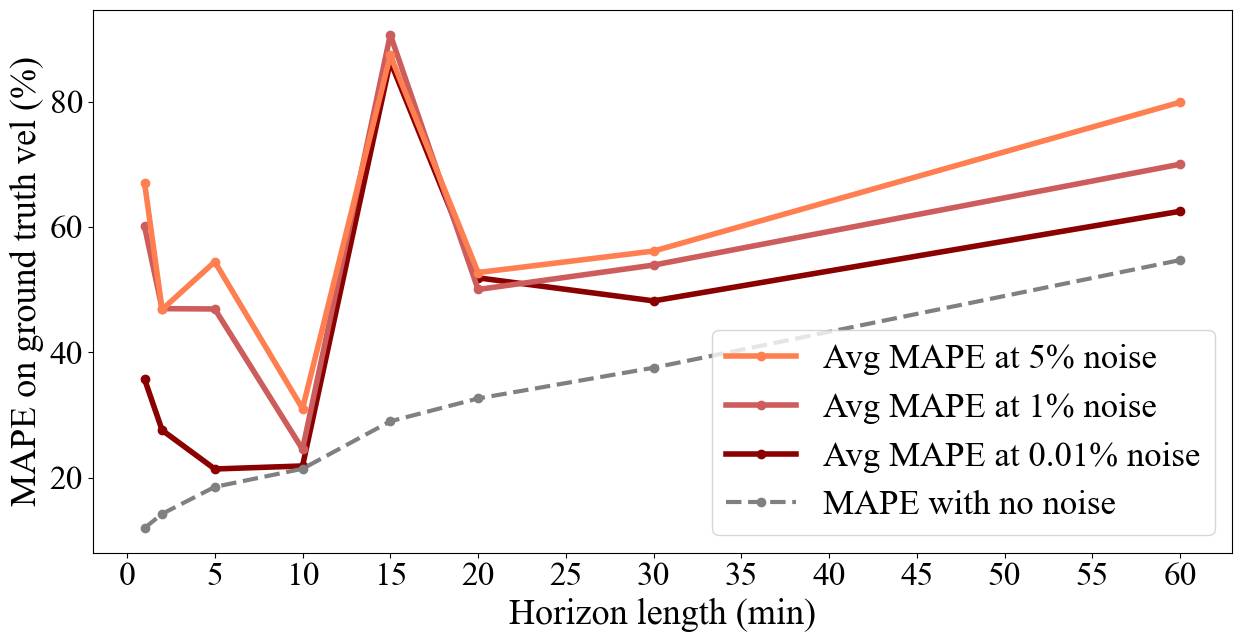

In [20]:
plot_mpc_acc_robustness("calibration/i24/i24_11_29/calibration_dynamic_smooth", [6, 12, 30, 60, 90, 120, 180, 360], percent_noise=[0.01, 1, 5], metric="mean", g_fontsize=26)

In [ ]:
# Plot sim vs gt error
sim_gt_error = np.abs(v_plot_true - dyn_v_sim).mean(axis=1)
plt.figure(figsize=(10, 4))
plt.plot(sim_gt_error)
plt.xlabel("Time Step")
plt.ylabel("Mean Absolute Error")